In [13]:
#importing modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

DATA_PATH = "../data/raw/train_data_enhanced.csv"

In [14]:
# loading data
df = pd.read_csv(DATA_PATH)

print(f"Rows / encounters : {len(df):,}")
print(f"Columns           : {df.shape[1]}")
print(f"Unique patients   : {df['patientid'].nunique():,}")
print(f"Unique case IDs   : {df['case_id'].nunique():,}")

df.head()

Rows / encounters : 318,438
Columns           : 35
Unique patients   : 92,017
Unique case IDs   : 318,438


,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available Extra Rooms in Hospital,Department,Ward_Type,Ward_Facility_Code,Bed Grade,...,days_since_previous_discharge,previous_30d_encounters,previous_90d_encounters,previous_365d_encounters,previous_hospital_days,previous_avg_los,previous_max_los,previous_readmission_count,previous_emergency_count,previous_urgent_count
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,...,NaN,0,0,0,0.000000,0.000000,0.000000,0,0,0
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,...,24.005949,0,1,1,6.551944,6.551944,6.551944,1,1,0
2,3,10,e,1,X,2,anesthesia,S,E,2.0,...,64.495069,0,0,2,56.985660,28.492830,50.433715,1,1,0
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,...,83.652674,0,0,3,96.403530,32.134510,50.433715,1,1,0
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,...,9.080961,0,1,4,145.772164,36.443041,50.433715,2,1,0


In [15]:
# checking any null values, etc etc in data
print("=== DATA TYPES ===")
print(df.dtypes.value_counts())

print("\n=== DUPLICATES ===")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate case IDs:", df["case_id"].duplicated().sum())

print("\n=== MISSING VALUES ===")

missing = (
    df.isna()
    .sum()
    .to_frame("missing_count")
)

missing["missing_%"] = (
    missing["missing_count"] / len(df) * 100
).round(2)

print(
    missing[missing["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

=== DATA TYPES ===
int64      15
str        11
float64     9
Name: count, dtype: int64

=== DUPLICATES ===
Duplicate rows: 0
Duplicate case IDs: 0

=== MISSING VALUES ===
                               missing_count  missing_%
days_to_next_admission                 92017      28.90
days_since_previous_discharge          92017      28.90
City_Code_Patient                       4532       1.42
Bed Grade                                113       0.04


Readmission Outcome Summary:


,count,percentage
readmission_group,,
Readmitted <30 Days,55454,17.41
Readmitted >30 Days,170967,53.69
Not Readmitted,92017,28.90


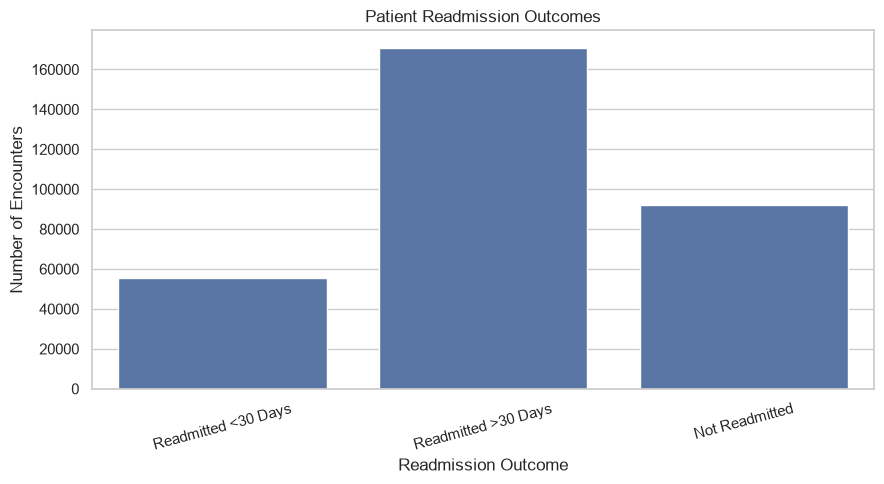

In [16]:
# reading admission of readmitted and non readmitted never admitted again in same hospital
def classify_readmission(days):
    if pd.isna(days):
        return "Not Readmitted"
    elif days <= 30:
        return "Readmitted <30 Days"
    else:
        return "Readmitted >30 Days"


# Create descriptive three-way readmission outcome
df["readmission_group"] = df["days_to_next_admission"].apply(
    classify_readmission
)

outcome_order = [
    "Readmitted <30 Days",
    "Readmitted >30 Days",
    "Not Readmitted"
]

# Summary table
outcome_summary = (
    df["readmission_group"]
    .value_counts()
    .reindex(outcome_order)
    .fillna(0)
    .to_frame("count")
)

outcome_summary["percentage"] = (
    outcome_summary["count"] / len(df) * 100
).round(2)

print("Readmission Outcome Summary:")
display(outcome_summary)


# Visualization
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="readmission_group",
    order=outcome_order
)

plt.title("Patient Readmission Outcomes")
plt.xlabel("Readmission Outcome")
plt.ylabel("Number of Encounters")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

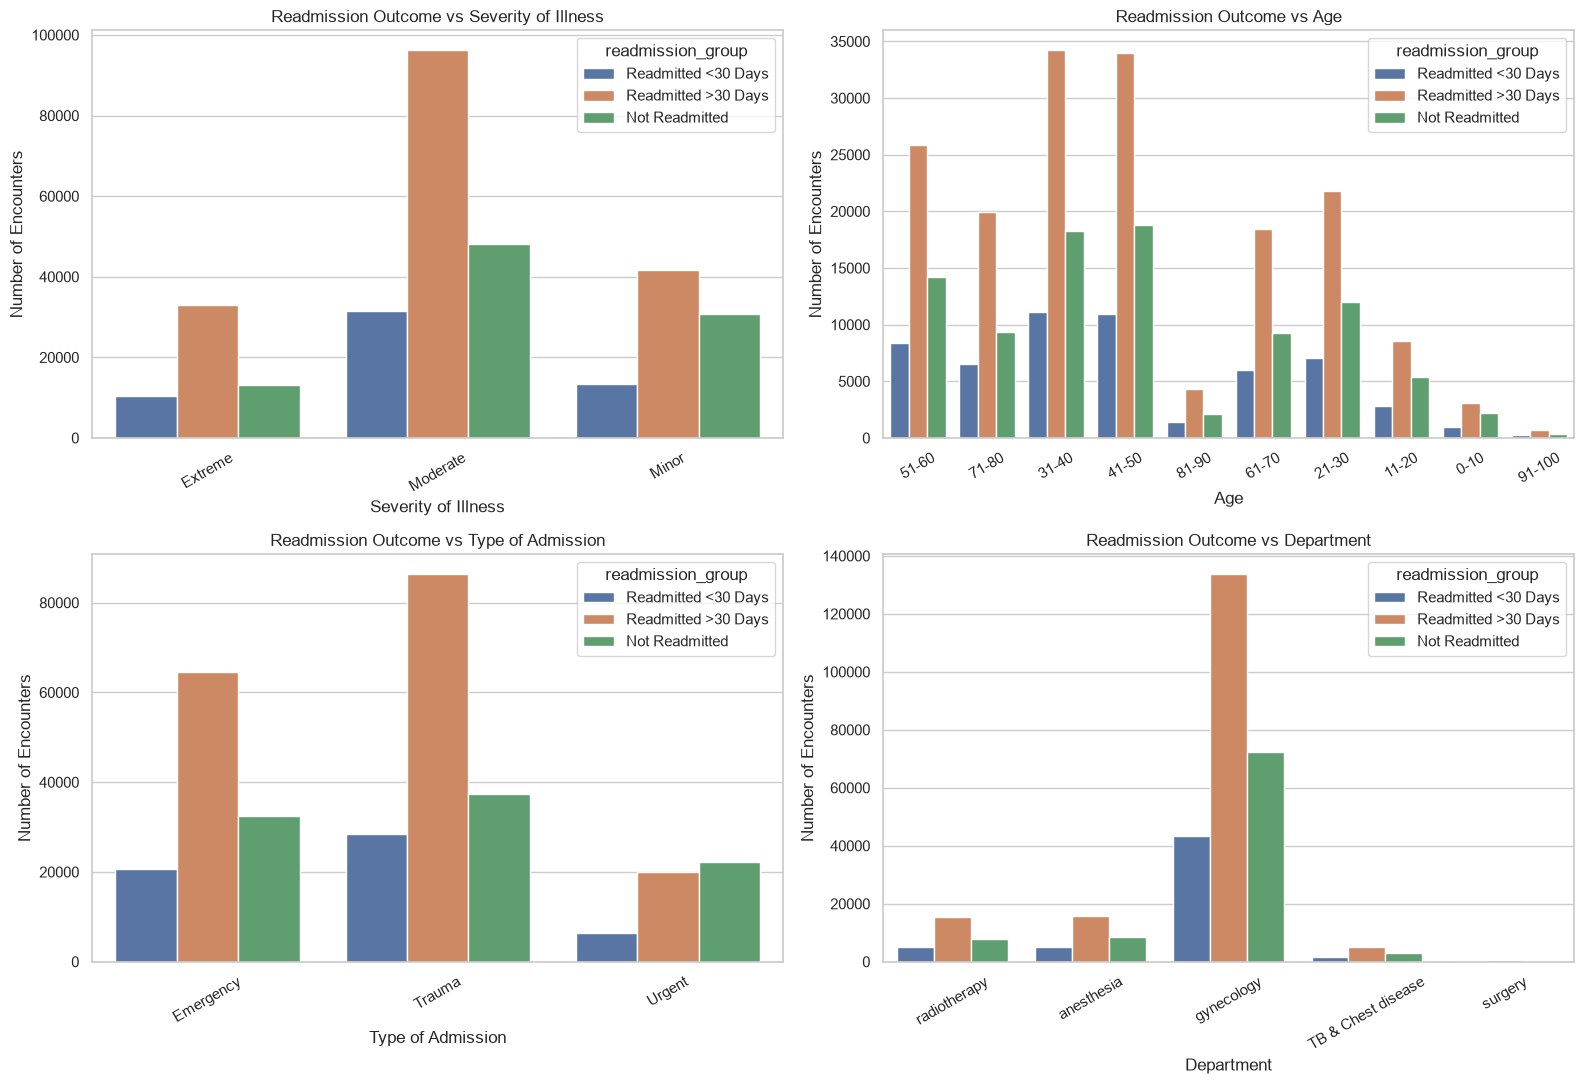

In [17]:
# filtering the features
features = [
    "Severity of Illness",
    "Age",
    "Type of Admission",
    "Department"
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 11)
)

for ax, feature in zip(axes.flat, features):

    sns.countplot(
        data=df,
        x=feature,
        hue="readmission_group",
        hue_order=outcome_order,
        ax=ax
    )

    ax.set_title(
        f"Readmission Outcome vs {feature}"
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Encounters")

    ax.tick_params(
        axis="x",
        rotation=30
    )

plt.tight_layout()
plt.show()

Average Previous Healthcare Utilization by Readmission Outcome:


,previous_encounters,previous_30d_encounters,previous_90d_encounters,previous_365d_encounters,previous_readmission_count,previous_hospital_days
readmission_group,,,,,,
Readmitted <30 Days,1.86,0.04,0.37,1.51,0.46,55.58
Readmitted >30 Days,1.86,0.04,0.36,1.51,0.45,55.73
Not Readmitted,2.46,0.04,0.41,1.90,0.60,74.47


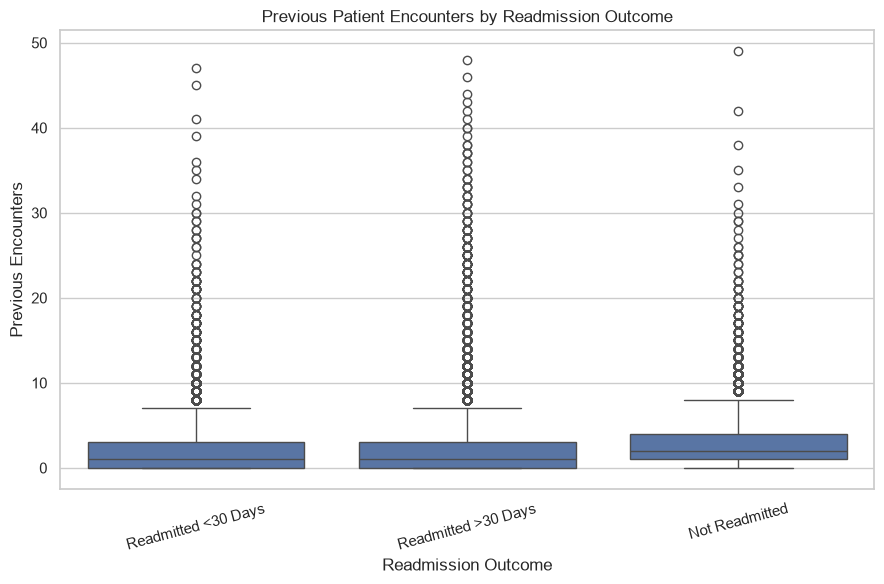

In [18]:
# checking paitient's history 
history_features = [
    "previous_encounters",
    "previous_30d_encounters",
    "previous_90d_encounters",
    "previous_365d_encounters",
    "previous_readmission_count",
    "previous_hospital_days"
]

# Compare average previous healthcare utilization across outcomes
history_summary = (
    df.groupby("readmission_group")[history_features]
    .mean()
    .reindex(outcome_order)
    .round(2)
)

print("Average Previous Healthcare Utilization by Readmission Outcome:")
display(history_summary)


# Visualize previous encounters across outcomes
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="readmission_group",
    y="previous_encounters",
    order=outcome_order
)

plt.title("Previous Patient Encounters by Readmission Outcome")
plt.xlabel("Readmission Outcome")
plt.ylabel("Previous Encounters")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

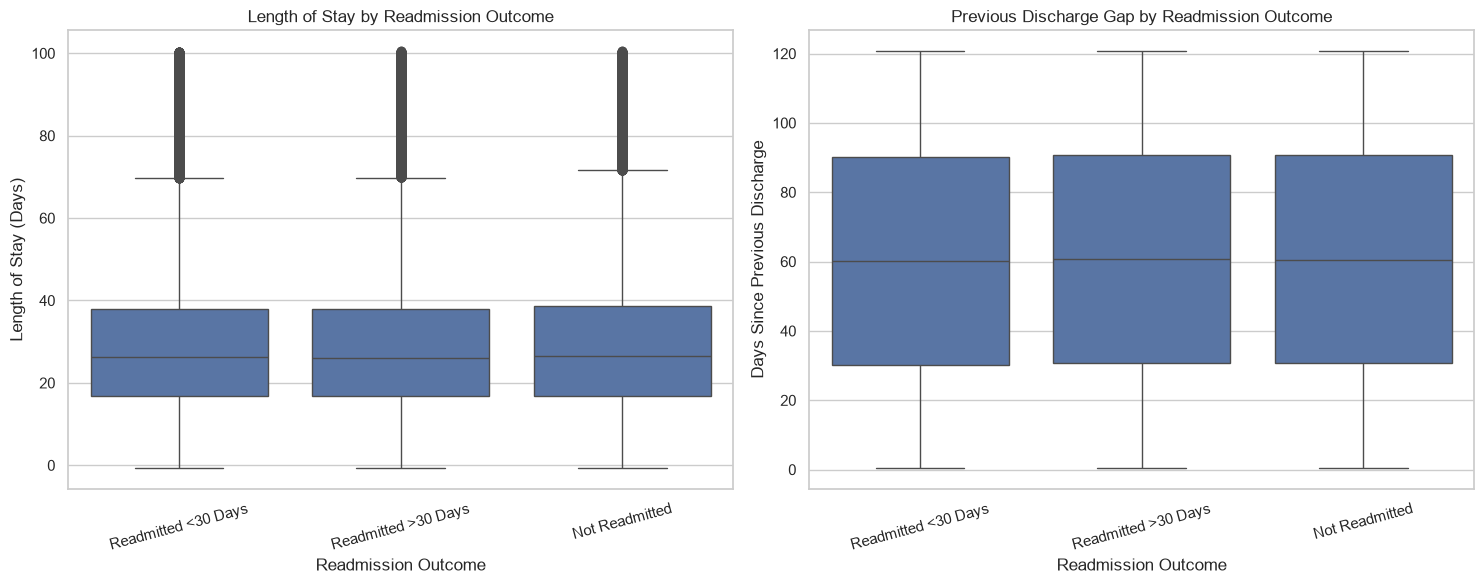

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(
    data=df,
    x="readmission_group",
    y="length_of_stay_days",
    order=outcome_order,
    ax=ax[0]
)

ax[0].set_title("Length of Stay by Readmission Outcome")
ax[0].set_xlabel("Readmission Outcome")
ax[0].set_ylabel("Length of Stay (Days)")
ax[0].tick_params(axis="x", rotation=15)


sns.boxplot(
    data=df,
    x="readmission_group",
    y="days_since_previous_discharge",
    order=outcome_order,
    ax=ax[1]
)

ax[1].set_title("Previous Discharge Gap by Readmission Outcome")
ax[1].set_xlabel("Readmission Outcome")
ax[1].set_ylabel("Days Since Previous Discharge")
ax[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

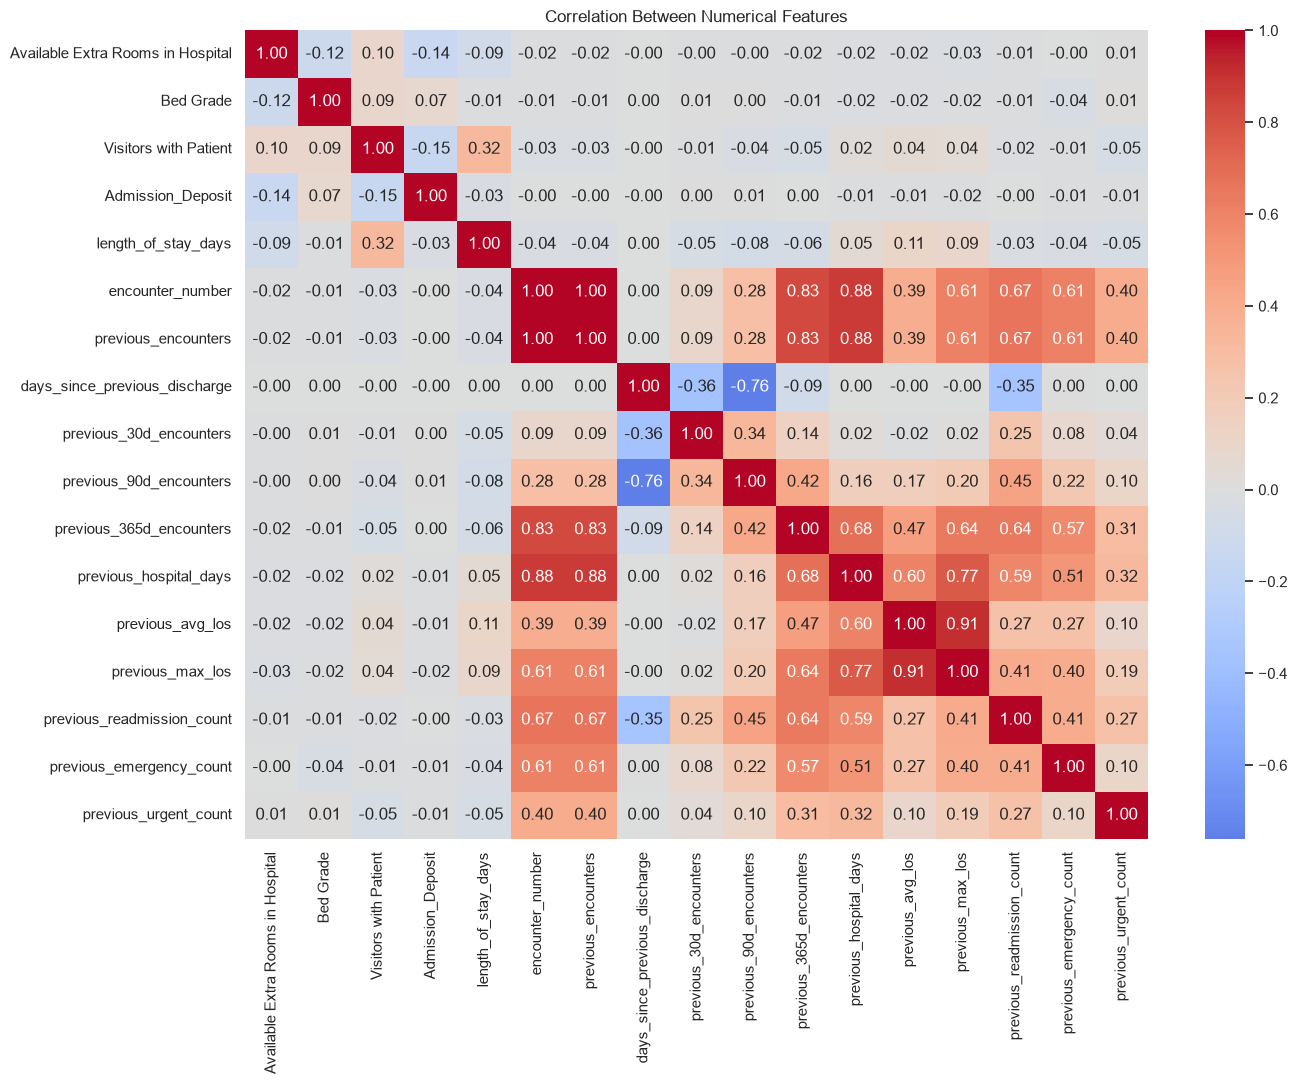


Strongest Numerical Feature Relationships:


,,correlation
encounter_number,previous_encounters,1.000000
previous_avg_los,previous_max_los,0.914397
previous_encounters,previous_hospital_days,0.879699
encounter_number,previous_hospital_days,0.879699
previous_encounters,previous_365d_encounters,0.830652
encounter_number,previous_365d_encounters,0.830652
previous_hospital_days,previous_max_los,0.771877
days_since_previous_discharge,previous_90d_encounters,-0.760975
previous_365d_encounters,previous_hospital_days,0.680177
previous_encounters,previous_readmission_count,0.669079


In [20]:
# Numerical correlation analysis
numeric_features = [
    "Available Extra Rooms in Hospital",
    "Bed Grade",
    "Visitors with Patient",
    "Admission_Deposit",
    "length_of_stay_days",
    "encounter_number",
    "previous_encounters",
    "days_since_previous_discharge",
    "previous_30d_encounters",
    "previous_90d_encounters",
    "previous_365d_encounters",
    "previous_hospital_days",
    "previous_avg_los",
    "previous_max_los",
    "previous_readmission_count",
    "previous_emergency_count",
    "previous_urgent_count"
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

correlation = df[numeric_features].corr()

plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"

)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


corr_pairs = (
    correlation
    .where(
        np.triu(
            np.ones(correlation.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .sort_values(key=abs, ascending=False)
)

print("\nStrongest Numerical Feature Relationships:")
display(corr_pairs.head(15).to_frame("correlation"))

In [21]:
admission = pd.to_datetime(
    df["synthetic_admission_datetime"],
    errors="coerce"
)

discharge = pd.to_datetime(
    df["synthetic_discharge_datetime"],
    errors="coerce"
)

print(
    "Missing admission datetime:",
    admission.isna().sum()
)

print(
    "Missing discharge datetime:",
    discharge.isna().sum()
)

print(
    "Discharge before admission:",
    (discharge < admission).sum()
)

print(
    "Negative length of stay:",
    (df["length_of_stay_days"] < 0).sum()
)

Missing admission datetime: 0
Missing discharge datetime: 0
Discharge before admission: 1257
Negative length of stay: 1257


In [22]:
# Columns that must not be used as predictive features
leakage_columns = [
    "days_to_next_admission",
    "synthetic_readmission_probability",
    "readmitted_30_days"
]

# Identifier columns used for grouping/identification, not prediction
identifier_columns = [
    "case_id",
    "patientid"
]

print("=== COLUMNS TO EXCLUDE FROM MODEL FEATURES ===\n")

print("Future / target-related columns:")
for col in leakage_columns:
    if col in df.columns:
        print(f"  - {col}")

print("\nIdentifier columns:")
for col in identifier_columns:
    if col in df.columns:
        print(f"  - {col}")


print("\n=== REASONS ===")
print("- readmitted_30_days → prediction target")
print("- days_to_next_admission → future information unavailable at prediction time")
print("- synthetic_readmission_probability → part of the synthetic target-generation process")
print("- case_id → encounter identifier")
print("- patientid → patient identifier; used for patient-level splitting, not prediction")

=== COLUMNS TO EXCLUDE FROM MODEL FEATURES ===

Future / target-related columns:
  - days_to_next_admission
  - readmitted_30_days

Identifier columns:
  - case_id
  - patientid

=== REASONS ===
- readmitted_30_days → prediction target
- days_to_next_admission → future information unavailable at prediction time
- synthetic_readmission_probability → part of the synthetic target-generation process
- case_id → encounter identifier
- patientid → patient identifier; used for patient-level splitting, not prediction
